# 02 · SARIMAX

SARIMA dengan variabel eksogen. Pemilihan model **hanya memakai data latih** (2016–2022) lewat AIC, lalu diuji sekali di 2023.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecasting import *

quiet()
setup_plot()
pd.options.display.float_format = '{:,.2f}'.format
import itertools
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [2]:
y = load_passengers()
train, test = y[:'2022'], y['2023']
X = make_exog(y.index)

## 1. Stasioneritas

In [3]:
for name, s in [('Data asli', train),
                ('Differencing ke-1', train.diff())]:
    stat, p, *_ = adfuller(s.dropna())
    print(f"{name:35s} ADF = {stat:6.2f}   p = {p:.4f}   {'stasioner' if p < 0.05 else 'tidak stasioner'}")

Data asli                           ADF =  -1.81   p = 0.3743   tidak stasioner
Differencing ke-1                   ADF =  -9.31   p = 0.0000   stasioner


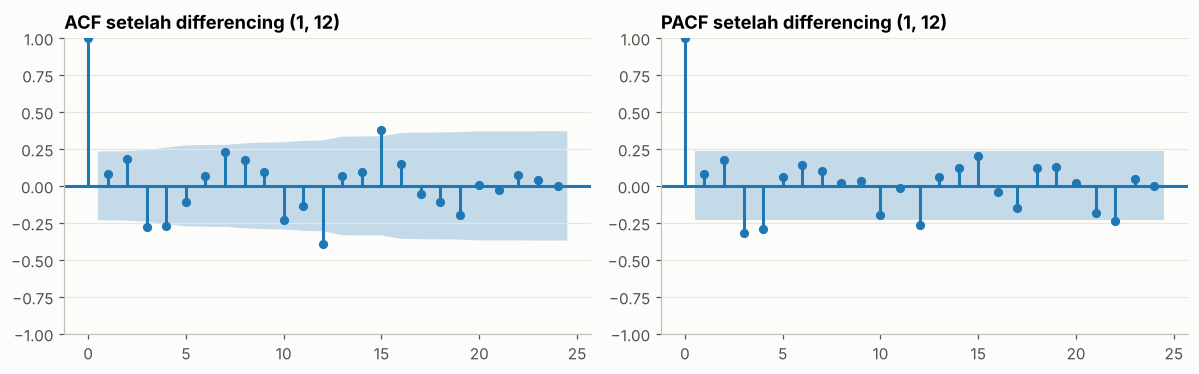

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
d = train.diff().diff(12).dropna()
plot_acf(d, lags=24, ax=axes[0]); plot_pacf(d, lags=24, ax=axes[1], method='ywm')
axes[0].set_title('ACF setelah differencing (1, 12)'); axes[1].set_title('PACF setelah differencing (1, 12)')
plt.tight_layout(); plt.show()

Data asli tidak stasioner (p = 0,37) dan menjadi stasioner setelah differencing pertama. Karena pola musiman 12 bulan juga kuat, dipakai differencing biasa dan musiman sekaligus (d = 1, D = 1), sama seperti skripsi. ACF dan PACF di atas dihitung setelah kedua differencing itu.

## 2. Pemilihan model dengan AIC (data latih saja)

Kandidat: p ∈ {0, 1}, q ∈ {0, 1, 2}, P ∈ {0, 1}, Q ∈ {0, 1}, dikombinasikan dengan empat set variabel eksogen. Total 96 model. AIC dihitung dari data latih, jadi data uji tidak ikut menentukan pilihan.

In [5]:
EXOG_SETS = {
    'tanpa eksogen': [],
    'covid': ['covid'],
    'covid + lebaran': ['covid', 'lebaran'],
    'covid + lebaran + jumlah_libur': ['covid', 'lebaran', 'jumlah_libur'],
}
rows = []
for exog_name, cols in EXOG_SETS.items():
    ex = X.loc[train.index, cols] if cols else None
    for p, q, P, Q in itertools.product([0, 1], [0, 1, 2], [0, 1], [0, 1]):
        try:
            r = fit_sarimax(train, (p, 1, q), (P, 1, Q, 12), ex)
            rows.append({'eksogen': exog_name, 'order': (p, 1, q), 'seasonal': (P, 1, Q, 12), 'AIC': r.aic})
        except Exception:
            pass
grid = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
grid.head(8)

,eksogen,order,seasonal,AIC
0,covid + lebaran,"(0, 1, 2)","(0, 1, 1, 12)","1,507.97"
1,covid + lebaran,"(0, 1, 2)","(1, 1, 1, 12)","1,508.38"
2,covid,"(0, 1, 2)","(0, 1, 1, 12)","1,508.40"
3,covid,"(0, 1, 2)","(1, 1, 1, 12)","1,508.59"
4,covid + lebaran,"(1, 1, 2)","(1, 1, 1, 12)","1,508.97"
5,covid + lebaran + jumlah_libur,"(0, 1, 2)","(0, 1, 1, 12)","1,509.10"
6,covid + lebaran + jumlah_libur,"(0, 1, 2)","(1, 1, 1, 12)","1,509.15"
7,covid,"(1, 1, 2)","(1, 1, 1, 12)","1,509.27"


In [6]:
best = grid.iloc[0]
cols = EXOG_SETS[best['eksogen']]
print('Model terpilih:', f"SARIMAX{best['order']}x{best['seasonal']}", '| eksogen:', best['eksogen'])
res = fit_sarimax(train, best['order'], best['seasonal'], X.loc[train.index, cols])
print(res.summary().tables[1])

Model terpilih: SARIMAX(0, 1, 2)x(0, 1, 1, 12) | eksogen: covid + lebaran
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid      -4.519e+05   6.73e+04     -6.716      0.000   -5.84e+05    -3.2e+05
lebaran     5.501e+04   9.24e+04      0.595      0.552   -1.26e+05    2.36e+05
ma.L1          0.0739      0.197      0.375      0.708      -0.312       0.460
ma.L2          0.3379      0.114      2.957      0.003       0.114       0.562
ma.S.L12      -0.4560      0.130     -3.510      0.000      -0.711      -0.201
sigma2      2.604e+10      0.642   4.06e+10      0.000     2.6e+10     2.6e+10


Model terpilih memiliki ordo ARIMA yang sama dengan model akhir skripsi, (0,1,2)(0,1,1)₁₂. Bedanya ada di variabel eksogen: `is_holiday` diganti `covid` dan `lebaran`.

Koefisien `covid` sangat signifikan (sekitar −450 ribu penumpang per bulan selama pembatasan). Koefisien `lebaran` positif tapi tidak signifikan (p ≈ 0,55): dengan hanya 7 bulan Lebaran di data latih, efeknya belum bisa diukur dengan presisi.

Catatan jujur: lima model teratas memiliki AIC yang selisihnya kurang dari 2, artinya secara statistik setara. Pilihan model terbaik di sini tidak setegas kelihatannya.

## 3. Diagnostik residual

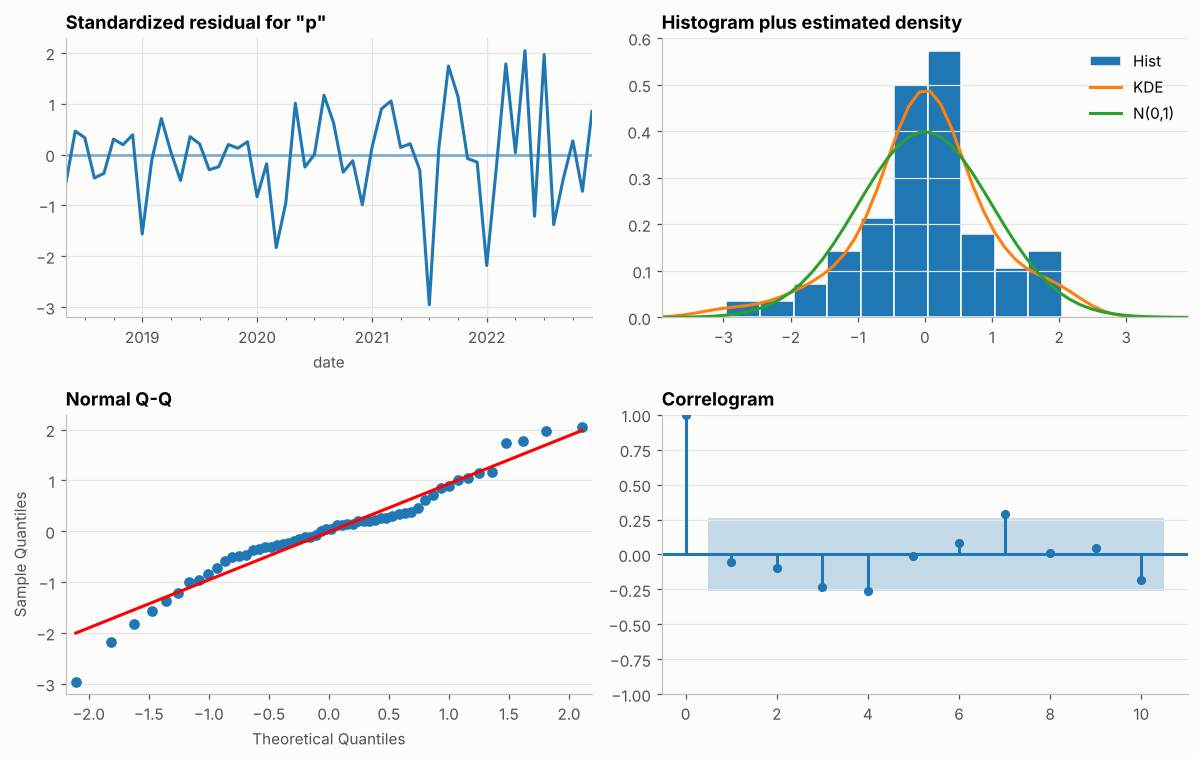

In [7]:
fig = res.plot_diagnostics(figsize=(11, 7))
plt.tight_layout(); plt.show()

In [8]:
from statsmodels.stats.diagnostic import acorr_ljungbox
acorr_ljungbox(res.resid[13:], lags=[6, 12])

,lb_stat,lb_pvalue
6,7.94,0.24
12,20.86,0.05


Pada lag 6 tidak ada autokorelasi residual yang signifikan (p = 0,24). Pada lag 12 nilainya tepat di batas (p ≈ 0,05), jadi masih ada sedikit pola yang belum tertangkap. Residual juga tidak berdistribusi normal karena guncangan COVID, sehingga selang kepercayaan ramalan perlu dibaca dengan hati-hati.

## 4. Ramalan 2023

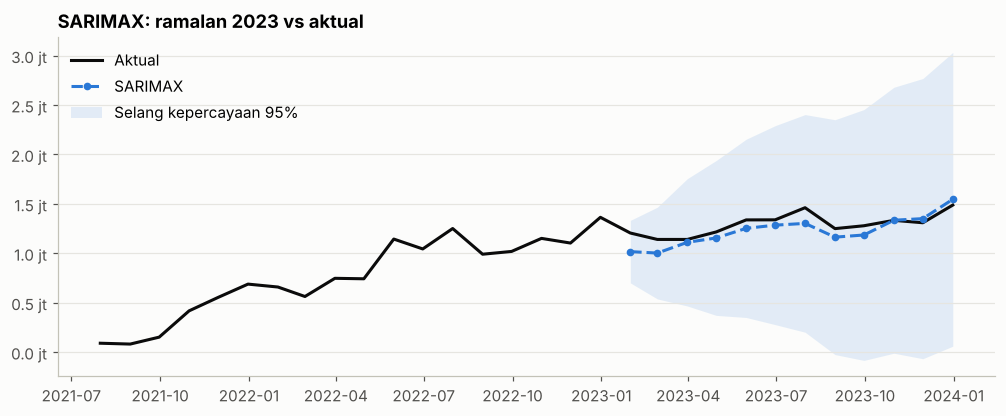

MAE        82,958.24
RMSE       98,233.37
MAPE (%)        6.50
dtype: float64

In [9]:
fc = res.get_forecast(12, exog=X.loc[test.index, cols])
sarimax_pred = fc.predicted_mean.to_numpy()
ci = fc.conf_int()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y['2021-07':].index, y['2021-07':].values, color=COLORS['Aktual'], label='Aktual')
ax.plot(test.index, sarimax_pred, color=COLORS['SARIMAX'], ls='--', marker='o', ms=4, label='SARIMAX')
ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], color=COLORS['SARIMAX'], alpha=0.12, lw=0, label='Selang kepercayaan 95%')
million_axis(ax); ax.legend(loc='upper left')
ax.set_title('SARIMAX: ramalan 2023 vs aktual')
plt.show()

pd.Series(metrics(test, sarimax_pred))

In [10]:
pd.DataFrame({'SARIMAX': sarimax_pred}, index=test.index).to_csv('../data/processed/ramalan_sarimax.csv', index_label='bulan')
grid.to_csv('../data/processed/sarimax_grid_aic.csv', index=False)